In [1]:
!pip install -q sentence-transformers scikit-learn matplotlib pandas numpy


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (15 outputs left out)

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

=== Hallucination vs. Faithfulness Detection Results ===
                        Method  ROC-AUC  PR-AUC  Faithful Mean  Hallucinated Mean  Separation Gap
        TF-IDF Lexical Overlap   0.0781  0.3168         0.3363             0.6607         -0.3244
    Bi-Encoder Cosine (MiniLM)   0.2812  0.3679         0.8338             0.8864         -0.0526
Cross-Encoder NLI (DeBERTa-v3)   1.0000  1.0000         0.9977             0.0099          0.9877


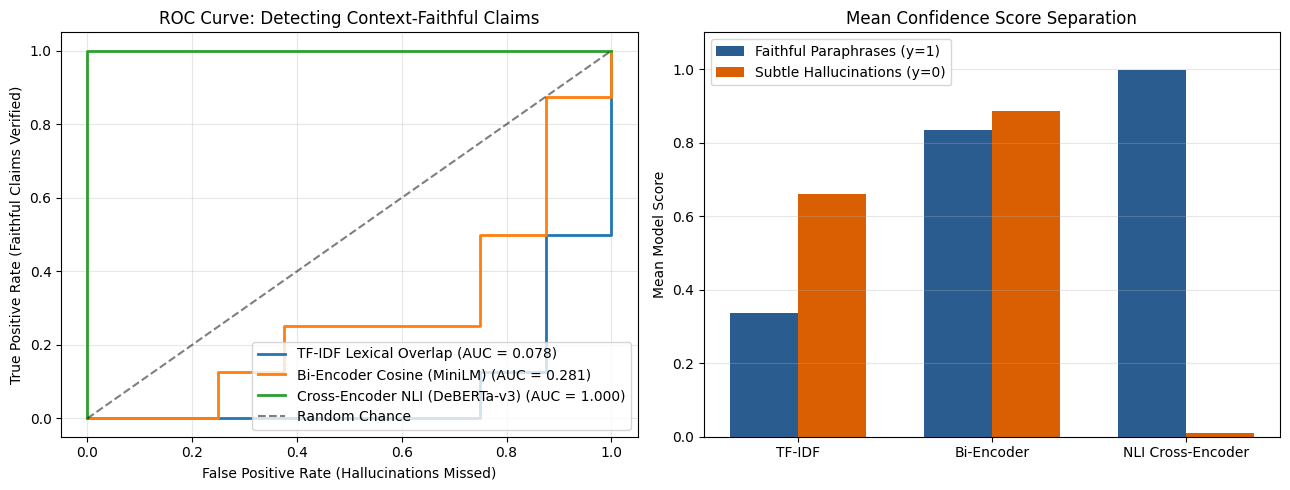

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer, CrossEncoder
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, roc_curve
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Evaluation Dataset (Context, Claim, Ground Truth: 1 = Faithful, 0 = Hallucinated/Contradiction)
benchmark_data = [
    # Faithful Paraphrases (Label = 1)
    ("The clinical trial enrolled 420 patients across 12 hospitals between March 2023 and January 2024.",
     "Between early 2023 and January 2024, 420 participants took part in the study across a dozen medical centers.", 1),
    ("Solar panel efficiency drops by roughly 0.4% for every degree Celsius increase above 25°C.",
     "Temperatures higher than 25 degrees Celsius reduce photovoltaic efficiency at a rate of about 0.4 percent per degree.", 1),
    ("The Apollo 11 lunar module Eagle landed on the Moon on July 20, 1969, with Neil Armstrong and Buzz Aldrin.",
     "Neil Armstrong and Buzz Aldrin touched down on the lunar surface aboard the Eagle module in July 1969.", 1),
    ("PostgreSQL 16 introduced parallelization for FULL and RIGHT OUTER hash joins to speed up analytical queries.",
     "Analytical query execution improved in PostgreSQL 16 via parallelized FULL and RIGHT OUTER hash joins.", 1),
    ("Arctic sea ice reaches its annual minimum extent each September after the summer melt season.",
     "Every September, following summer melting, Arctic sea ice hits its lowest yearly coverage.", 1),
    ("The enzyme lactase breaks down lactose into two simpler sugars: glucose and galactose.",
     "Glucose and galactose are produced when lactase hydrolyzes lactose.", 1),
    ("HTTP/3 replaces TCP with QUIC over UDP to eliminate head-of-line blocking at the transport layer.",
     "By running QUIC on top of UDP instead of TCP, HTTP/3 avoids transport-layer head-of-line blocking.", 1),
    ("Gradient clipping prevents exploding gradients during backpropagation by rescaling parameter updates above a threshold.",
     "When gradient norms exceed a set threshold, gradient clipping rescales them to stop instability in backprop.", 1),

    # Subtle Hallucinations & Contradictions (Label = 0)
    ("The clinical trial enrolled 420 patients across 12 hospitals between March 2023 and January 2024.",
     "The clinical trial enrolled 420 patients across 21 hospitals between March 2023 and January 2024.", 0),
    ("Solar panel efficiency drops by roughly 0.4% for every degree Celsius increase above 25°C.",
     "Solar panel efficiency increases by roughly 0.4% for every degree Celsius rise above 25°C.", 0),
    ("The Apollo 11 lunar module Eagle landed on the Moon on July 20, 1969, with Neil Armstrong and Buzz Aldrin.",
     "Michael Collins and Neil Armstrong landed the Eagle lunar module on the Moon on July 20, 1969.", 0),
    ("PostgreSQL 16 introduced parallelization for FULL and RIGHT OUTER hash joins to speed up analytical queries.",
     "PostgreSQL 15 introduced parallelization for FULL and RIGHT OUTER hash joins to speed up transactional writes.", 0),
    ("Arctic sea ice reaches its annual minimum extent each September after the summer melt season.",
     "Arctic sea ice reaches its maximum annual extent each September right before the winter freeze.", 0),
    ("The enzyme lactase breaks down lactose into two simpler sugars: glucose and galactose.",
     "The enzyme lactase breaks down sucrose into two simpler sugars: glucose and fructose.", 0),
    ("HTTP/3 replaces TCP with QUIC over UDP to eliminate head-of-line blocking at the transport layer.",
     "HTTP/3 upgrades TCP with QUIC to eliminate head-of-line blocking at the application layer.", 0),
    ("Gradient clipping prevents exploding gradients during backpropagation by rescaling parameter updates above a threshold.",
     "Gradient clipping prevents vanishing gradients during forward propagation by amplifying small weights.", 0),
]

df = pd.DataFrame(benchmark_data, columns=["context", "claim", "is_faithful"])

# 2. Method A: Lexical Baseline (TF-IDF Cosine Similarity)
vectorizer = TfidfVectorizer()
tfidf_scores = []
for _, row in df.iterrows():
    vecs = vectorizer.fit_transform([row["context"], row["claim"]])
    tfidf_scores.append(cosine_similarity(vecs[0], vecs[1])[0][0])
df["tfidf_score"] = tfidf_scores

# 3. Method B: Dense Bi-Encoder Semantic Similarity (all-MiniLM-L6-v2)
bi_encoder = SentenceTransformer("all-MiniLM-L6-v2")
ctx_emb = bi_encoder.encode(df["context"].tolist(), normalize_embeddings=True)
clm_emb = bi_encoder.encode(df["claim"].tolist(), normalize_embeddings=True)
df["bi_encoder_score"] = np.sum(ctx_emb * clm_emb, axis=1)

# 4. Method C: Cross-Encoder NLI Entailment Scorer (nli-deberta-v3-small)
# Label mapping for cross-encoder/nli-deberta-v3-small: 0 = contradiction, 1 = entailment, 2 = neutral
nli_model = CrossEncoder("cross-encoder/nli-deberta-v3-small")
pairs = list(zip(df["context"], df["claim"]))
logits = nli_model.predict(pairs)
probs = np.exp(logits) / np.sum(np.exp(logits), axis=1, keepdims=True)
df["nli_entailment_score"] = probs[:, 1]
df["nli_contradiction_prob"] = probs[:, 0]

# 5. Quantitative Evaluation Table (ROC-AUC and PR-AUC)
methods = {
    "TF-IDF Lexical Overlap": df["tfidf_score"],
    "Bi-Encoder Cosine (MiniLM)": df["bi_encoder_score"],
    "Cross-Encoder NLI (DeBERTa-v3)": df["nli_entailment_score"]
}

print("=== Hallucination vs. Faithfulness Detection Results ===")
results_summary = []
for name, scores in methods.items():
    roc_auc = roc_auc_score(df["is_faithful"], scores)
    prec, rec, _ = precision_recall_curve(df["is_faithful"], scores)
    pr_auc = auc(rec, prec)
    mean_faithful = scores[df["is_faithful"] == 1].mean()
    mean_halluc = scores[df["is_faithful"] == 0].mean()
    gap = mean_faithful - mean_halluc
    results_summary.append({
        "Method": name,
        "ROC-AUC": round(roc_auc, 4),
        "PR-AUC": round(pr_auc, 4),
        "Faithful Mean": round(mean_faithful, 4),
        "Hallucinated Mean": round(mean_halluc, 4),
        "Separation Gap": round(gap, 4)
    })

summary_df = pd.DataFrame(results_summary)
print(summary_df.to_string(index=False))

# 6. Dual-Panel Research Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Panel 1: ROC Curves
for name, scores in methods.items():
    fpr, tpr, _ = roc_curve(df["is_faithful"], scores)
    score_auc = roc_auc_score(df["is_faithful"], scores)
    ax1.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {score_auc:.3f})")

ax1.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Chance")
ax1.set_title("ROC Curve: Detecting Context-Faithful Claims")
ax1.set_xlabel("False Positive Rate (Hallucinations Missed)")
ax1.set_ylabel("True Positive Rate (Faithful Claims Verified)")
ax1.legend(loc="lower right")
ax1.grid(alpha=0.3)

# Panel 2: Score Distribution Comparison
x_labels = ["TF-IDF", "Bi-Encoder", "NLI Cross-Encoder"]
faithful_means = [summary_df.loc[i, "Faithful Mean"] for i in range(3)]
halluc_means = [summary_df.loc[i, "Hallucinated Mean"] for i in range(3)]

x = np.arange(len(x_labels))
width = 0.35
ax2.bar(x - width/2, faithful_means, width, label="Faithful Paraphrases (y=1)", color="#2b5c8f")
ax2.bar(x + width/2, halluc_means, width, label="Subtle Hallucinations (y=0)", color="#d95f02")
ax2.set_title("Mean Confidence Score Separation")
ax2.set_xticks(x)
ax2.set_xticklabels(x_labels)
ax2.set_ylabel("Mean Model Score")
ax2.set_ylim(0, 1.1)
ax2.legend()
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("rag_faithfulness_results.png", dpi=300)
plt.show()